**REGRESIÓN LOGÍSTICA MULTINOMIAL SOBRE LA HOJA Negocios_CRM**

En este cuaderno se aplica una regresión logística multinomial a la hoja Negocios_CRM del archivo Datos_CLV_2026_Tec_v2.xlsx.

La variable objetivo es el desenlace del negocio, construida a partir de nombre_etapa y agrupada en tres categorías: Ganado, Perdido y En proceso. El propósito es estimar en cuál de esos tres desenlaces termina una oportunidad comercial a partir de su valor, su actividad registrada, su antigüedad, su canal y su responsable.

La hoja requiere limpieza previa, por lo que el cuaderno inicia con una sección de preprocesamiento.

In [1]:
# Cargamos librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    accuracy_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
# Cargamos la hoja Negocios_CRM del archivo de Excel
df = pd.read_excel("Datos_CLV_2026_Tec_v2.xlsx", sheet_name="Negocios_CRM")

In [3]:
df.head()

,id_negocio,nombre_negocio,estado,tipo_negocio,nombre_etapa,estatus,fecha_creacion,fecha_creacion_id,fecha_cierre,numero_actividades,valor_previsto,id_usuario_creador,vendedor,valor_negocio,nombre_pipeline,oportunidad_ruta,ultima_modificacion,motivo_cierre_perdido,nombre_zona,Unnamed: 19
0,60966213634,Innovacion En Diseño Y Manofactura / Fresas / Qro,Querétaro,Cliente existente,Cierre Ganado,Cerrado,2026-06-08T21:50:42.257Z,20260608,2026-06-08T22:53:13.159Z,0,3853.43,93271593.0,Fernanda Pacheco,3853.43,Pipeline De Ventas,No,2026-07-29T00:00:00Z,NaN,Zona Noreste,NaN
1,60964805197,Doctores Bahena / Colorimetro / Qro,Querétaro,Cliente existente,Cierre Perdido,Cerrado,2026-06-09T00:12:48.684Z,20260609,2026-06-24T20:39:32.277Z,0,2439.66,93271593.0,Fernanda Pacheco,2439.66,Pipeline De Ventas,No,2026-07-29T00:00:00Z,No tiene el dinero,Zona Noreste,NaN
2,60964799543,Jesus Israel Lopez Casas/ 6000mp Tytan Max / Qro,Querétaro,Cliente existente,Cierre Ganado,Cerrado,2026-06-08T22:20:22.148Z,20260608,2026-06-24T22:13:35.26Z,2,151724.14,93271593.0,Fernanda Pacheco,151724.14,Pipeline De Ventas,No,2026-07-29T00:00:00Z,NaN,Zona Noreste,NaN
3,60964785012,Esthetic Dental Project / Asiga / Qro,Querétaro,Cliente existente,Cierre Ganado,Cerrado,2026-06-08T19:06:34.126Z,20260608,2026-06-09T22:22:07.18Z,0,15689.66,93271593.0,Fernanda Pacheco,15689.66,Pipeline De Ventas,No,2026-07-29T00:00:00Z,NaN,Zona Noreste,NaN
4,60962206830,Innovacion En Diseño Y Manufactura Dental / Di...,Querétaro,Cliente existente,Cierre Ganado,Cerrado,2026-06-08T18:23:55.735Z,20260608,2026-06-08T21:06:47.96Z,0,5534.50,93271593.0,Fernanda Pacheco,5534.5,Pipeline De Ventas,No,2026-07-29T00:00:00Z,NaN,Zona Noreste,NaN


In [4]:
# Revisamos el tamaño de la hoja y el tipo de dato de cada columna
print('Registros y columnas:')
print(df.shape)
df.info()

Registros y columnas:
(5268, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5268 entries, 0 to 5267
Data columns (total 20 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_negocio             5268 non-null   int64  
 1   nombre_negocio         5268 non-null   object 
 2   estado                 5119 non-null   object 
 3   tipo_negocio           4708 non-null   object 
 4   nombre_etapa           5246 non-null   object 
 5   estatus                5268 non-null   object 
 6   fecha_creacion         5268 non-null   object 
 7   fecha_creacion_id      5268 non-null   object 
 8   fecha_cierre           5223 non-null   object 
 9   numero_actividades     5251 non-null   object 
 10  valor_previsto         5268 non-null   float64
 11  id_usuario_creador     5061 non-null   float64
 12  vendedor               4862 non-null   object 
 13  valor_negocio          5247 non-null   object 
 14  nombre_pipeline        

In [5]:
# Revisamos los valores nulos de cada columna
df.isna().sum()

id_negocio                  0
nombre_negocio              0
estado                    149
tipo_negocio              560
nombre_etapa               22
estatus                     0
fecha_creacion              0
fecha_creacion_id           0
fecha_cierre               45
numero_actividades         17
valor_previsto              0
id_usuario_creador        207
vendedor                  406
valor_negocio              21
nombre_pipeline             0
oportunidad_ruta            0
ultima_modificacion         0
motivo_cierre_perdido    4381
nombre_zona              1142
Unnamed: 19              5254
dtype: int64

**PREPROCESAMIENTO**

La hoja presenta cuatro problemas que deben resolverse antes de modelar: una columna sin nombre, un grupo de registros con las columnas desalineadas, columnas numéricas almacenadas como texto y categorías con valores que no corresponden a la columna.

In [6]:
# La columna Unnamed: 19 no forma parte del diccionario de datos
# Contiene valores de zona que se desplazaron desde la columna anterior
print('Valores de la columna sin nombre:')
print(df['Unnamed: 19'].value_counts(dropna=False))

Valores de la columna sin nombre:
Unnamed: 19
NaN                              5254
Zona Sur Este Golfo de México       9
Zona Metropolitana                  5
Name: count, dtype: int64


In [7]:
# Eliminamos la columna sin nombre
df = df.drop(columns=['Unnamed: 19'])

In [8]:
# Detectamos los registros con las columnas desalineadas
# Un grupo se reconoce porque numero_actividades contiene una fecha en lugar de un entero
# Otro grupo se reconoce porque fecha_creacion contiene un texto de estatus
actividades = pd.to_numeric(df['numero_actividades'], errors='coerce')
fechas = pd.to_datetime(df['fecha_creacion'], errors='coerce', utc=True, format='ISO8601')
desalineados = (actividades.isna() & df['numero_actividades'].notna()) | fechas.isna()
print('Registros desalineados:')
print(desalineados.sum())
df.loc[desalineados, ['nombre_negocio', 'estado', 'numero_actividades', 'fecha_creacion']].head(10)

Registros desalineados:
23


,nombre_negocio,estado,numero_actividades,fecha_creacion
1495,Erick Emanuel,| Ciudad De México | Hornos De Cocción,NaN,Abierto
1496,Corporativo Dental,| Hidalgo |,NaN,Abierto
1505,Maria Elena,| Ciudad De México | Resinas De Impresión,NaN,Abierto
1566,Elisa Esperanza,| Ciudad De México | Maquillaje Y Caracteri...,NaN,Abierto
1570,Hassan,| Ciudad De México | Maquillaje,NaN,Abierto
2343,Angélica,| Tlaxcala |,2026-06-15T18:56:21.264Z,Cerrado
2348,Carlos Alberto Lozano,| Tabasco | Escáner Intraoral,2026-08-20T15:16:05.338Z,Cerrado
2413,Yamileth,| Tlaxcala |,2026-06-15T18:55:05.672Z,Cerrado
2948,Rafael,| Yucatán | Fresadoras,NaN,Abierto
2949,Laura,| Yucatán | Escáner Intraoral,NaN,Abierto


In [9]:
# Eliminamos los registros desalineados porque sus campos no son recuperables
df = df.loc[~desalineados].copy()
print('Registros restantes:')
print(len(df))

Registros restantes:
5245


In [10]:
# Convertimos a número las columnas que llegaron como texto
df['numero_actividades'] = pd.to_numeric(df['numero_actividades'], errors='coerce').fillna(0)
df['valor_negocio'] = pd.to_numeric(df['valor_negocio'], errors='coerce')
df['valor_previsto'] = pd.to_numeric(df['valor_previsto'], errors='coerce').fillna(0)

In [11]:
# Verificamos si valor_negocio y valor_previsto contienen la misma información
iguales = (df['valor_previsto'] == df['valor_negocio']).sum()
print('Registros donde valor_previsto coincide con valor_negocio:')
print(iguales, 'de', df['valor_negocio'].notna().sum())

Registros donde valor_previsto coincide con valor_negocio:
5245 de 5245


In [12]:
# Las dos columnas son equivalentes, conservamos solo valor_previsto
df = df.drop(columns=['valor_negocio'])

In [13]:
# Convertimos las columnas de fecha
# El reporte mezcla marcas de tiempo con y sin milisegundos, por eso se indica ISO8601
df['fecha_creacion'] = pd.to_datetime(df['fecha_creacion'], errors='coerce', utc=True, format='ISO8601')
df['fecha_cierre'] = pd.to_datetime(df['fecha_cierre'], errors='coerce', utc=True, format='ISO8601')
print('Rango de fechas de creación:')
print(df['fecha_creacion'].min(), 'a', df['fecha_creacion'].max())

Rango de fechas de creación:
2025-08-05 22:27:33.424000+00:00 a 2026-09-04 01:01:48.242000+00:00


In [14]:
# Construimos las variables derivadas
# La fecha de corte es la última creación registrada en la hoja
fecha_corte = df['fecha_creacion'].max()
df['antiguedad_dias'] = (fecha_corte - df['fecha_creacion']).dt.total_seconds() / 86400
df['mes_creacion'] = df['fecha_creacion'].dt.month
df['log_valor'] = np.log1p(df['valor_previsto'])
df['tiene_valor'] = (df['valor_previsto'] > 0).astype(int)
print('Fecha de corte:')
print(fecha_corte)

Fecha de corte:
2026-09-04 01:01:48.242000+00:00


In [15]:
# El 83 por ciento de los negocios tiene valor cero, por eso separamos
# la magnitud del monto de la simple presencia de un monto
print('Negocios con valor previsto mayor que cero:')
print(df['tiene_valor'].sum(), 'de', len(df))

Negocios con valor previsto mayor que cero:
900 de 5245


In [16]:
# Revisamos las categorías de las columnas que se usarán como predictoras
for columna in ['tipo_negocio', 'nombre_pipeline', 'oportunidad_ruta', 'nombre_zona']:
    print('---', columna)
    print(df[columna].value_counts(dropna=False))
    print()

--- tipo_negocio
tipo_negocio
Cliente existente    3817
Cliente nuevo         888
NaN                   540
Name: count, dtype: int64

--- nombre_pipeline
nombre_pipeline
Pipeline De Ventas    4385
Ventas - Main          719
Mapeo En Ruta          117
Educación Contínua      24
Name: count, dtype: int64

--- oportunidad_ruta
oportunidad_ruta
No    5208
Si      37
Name: count, dtype: int64

--- nombre_zona
nombre_zona
Zona Metropolitana               1555
Zona Sur Este Golfo de México    1261
NaN                              1120
Zona Bajío                        720
Zona Occidente Pacífico           434
Zona Noreste                      155
Name: count, dtype: int64



In [17]:
# Las columnas categóricas contienen valores que pertenecen a otras columnas
# Conservamos únicamente las categorías válidas y el resto queda como nulo
df['tipo_negocio'] = df['tipo_negocio'].where(
    df['tipo_negocio'].isin(['Cliente existente', 'Cliente nuevo']))

df['nombre_pipeline'] = df['nombre_pipeline'].where(
    df['nombre_pipeline'].isin(['Pipeline De Ventas', 'Ventas - Main',
                                'Mapeo En Ruta', 'Educación Contínua']))

df['oportunidad_ruta'] = df['oportunidad_ruta'].where(
    df['oportunidad_ruta'].isin(['No', 'Si', 'Mapeo En Ruta']))

df['nombre_zona'] = df['nombre_zona'].where(
    df['nombre_zona'].isin(['Zona Metropolitana', 'Zona Sur Este Golfo de México',
                            'Zona Bajío', 'Zona Occidente Pacífico', 'Zona Noreste']))

In [18]:
# El vendedor es relevante para el cierre, pero tiene 32 categorías
# Agrupamos en Otros a los vendedores con menos de 30 negocios registrados
conteo_vendedor = df['vendedor'].value_counts()
vendedores_frecuentes = conteo_vendedor[conteo_vendedor >= 30].index
df['vendedor'] = df['vendedor'].where(df['vendedor'].isin(vendedores_frecuentes), 'Otros')
print('Categorías de vendedor conservadas:')
print(len(vendedores_frecuentes))

Categorías de vendedor conservadas:
23


In [19]:
# Rellenamos los nulos de las columnas categóricas con una categoría propia
# Un dato ausente en el CRM es informativo, no equivale a un valor promedio
for columna in ['tipo_negocio', 'nombre_pipeline', 'oportunidad_ruta', 'nombre_zona']:
    df[columna] = df[columna].fillna('Sin dato')

**CONSTRUCCIÓN DE LA VARIABLE OBJETIVO**

La columna nombre_etapa contiene 19 etapas distintas, varias de ellas con menos de diez registros y con nombres duplicados por errores de captura. Agrupamos esas etapas en tres desenlaces para obtener categorías con volumen suficiente.

In [20]:
# Revisamos los valores de la columna de etapa
df['nombre_etapa'].value_counts(dropna=False)

nombre_etapa
Cierre Ganado                      3763
Cierre Perdido                      691
Ganado                              336
Perdido                             243
Negociación                          42
Lead                                 38
Cotización                           32
Calificado Para Comprar              26
Contactado                           25
Envío De Cotización                  12
Necesidad Descubierta                11
Rgistro                               9
Informacion Enviada                   6
Recepción De Pago / Financiera        6
Envío De Cotización/Negociación       2
Recepción De Pago                     1
En Espera De Pago                     1
Turnado                               1
Name: count, dtype: int64

In [21]:
# Agrupamos las etapas en tres desenlaces
# Las etapas intermedias forman la categoría En proceso
mapa_desenlace = {
    'Cierre Ganado': 'Ganado',
    'Ganado': 'Ganado',
    'Recepción De Pago': 'Ganado',
    'Cierre Perdido': 'Perdido',
    'Perdido': 'Perdido'
}
df['desenlace'] = df['nombre_etapa'].map(mapa_desenlace)
etapas_intermedias = df['nombre_etapa'].notna() & df['desenlace'].isna()
df.loc[etapas_intermedias, 'desenlace'] = 'En proceso'

In [22]:
# Revisamos los valores de la variable objetivo
df['desenlace'].value_counts(dropna=False)

desenlace
Ganado        4100
Perdido        934
En proceso     211
Name: count, dtype: int64

In [23]:
# Eliminamos los registros que no tienen categoría objetivo
df = df.dropna(subset=['desenlace']).copy()
print('Registros disponibles para el modelo:')
print(len(df))

Registros disponibles para el modelo:
5245


In [24]:
# Rellenamos con la mediana los nulos que pudieran quedar en las variables numéricas
for columna in ['numero_actividades', 'antiguedad_dias', 'mes_creacion', 'log_valor']:
    df[columna] = df[columna].fillna(df[columna].median())
print('Nulos restantes en las variables numéricas:')
print(df[['numero_actividades', 'antiguedad_dias', 'mes_creacion', 'log_valor']].isna().sum().sum())

Nulos restantes en las variables numéricas:
0


**SELECCIÓN DE VARIABLES PREDICTORAS**

Tres columnas de la hoja anticipan el desenlace porque se escriben después de que el negocio se cierra, por lo que se excluyen del modelo.

La columna estatus distingue entre Cerrado y Abierto, lo que equivale a separar los desenlaces definitivos de los que siguen en proceso. La columna motivo_cierre_perdido solo se captura cuando el negocio se pierde, de modo que su presencia identifica la categoría Perdido. La columna fecha_cierre guarda la fecha real para los negocios cerrados y la fecha estimada para los abiertos, por lo que cualquier variable derivada de ella mezcla dos significados distintos.

También se excluyen los identificadores, el nombre del negocio por ser texto libre, la fecha de última modificación por corresponder a la extracción del reporte, y la columna estado por representar la misma información geográfica que nombre_zona con mayor dispersión.

In [25]:
# Declaramos las variables dependientes e independientes
# No incluimos estatus, motivo_cierre_perdido ni fecha_cierre por anticipar el desenlace
variables_numericas = ['numero_actividades', 'log_valor', 'tiene_valor',
                       'antiguedad_dias', 'mes_creacion']
variables_categoricas = ['tipo_negocio', 'nombre_pipeline', 'oportunidad_ruta',
                         'nombre_zona', 'vendedor']

Vars_Indep = df[variables_numericas + variables_categoricas]
Var_Dep = df['desenlace']

In [26]:
# Convertimos las variables categóricas en variables indicadoras
Vars_Indep = pd.get_dummies(Vars_Indep, columns=variables_categoricas, drop_first=True).astype(float)
print('Variables predictoras después de la codificación:')
print(Vars_Indep.shape)

Variables predictoras después de la codificación:
(5245, 39)


In [27]:
#Redefinimos las variables
X = Vars_Indep
y = Var_Dep

In [28]:
# Dividimos el conjunto de datos en entrenamiento y prueba
# stratify conserva, en lo posible, la proporción de cada clase
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=42, stratify=y)

In [29]:
#Se escalan todos los datos
escalar = StandardScaler()

In [30]:
# Ajustamos el escalador con los datos de entrenamiento
# y aplicamos la misma transformación a los datos de prueba
X_train = escalar.fit_transform(X_train)
X_test = escalar.transform(X_test)

In [31]:
# Definimos el algoritmo de regresión logística multinomial
# Con más de dos clases, scikit-learn ajusta el modelo multinomial
algoritmo = LogisticRegression(
    solver='lbfgs',
    max_iter=2000
)

In [32]:
#Entrenamos el modelo
algoritmo.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [33]:
#Realizamos una predicción
y_pred = algoritmo.predict(X_test)
y_pred

array(['Ganado', 'Ganado', 'Ganado', ..., 'Ganado', 'Ganado', 'Ganado'],
      shape=(1574,), dtype=object)

In [34]:
# Consultamos las categorías que predice el modelo
print('Clases del modelo:')
print(algoritmo.classes_)

Clases del modelo:
['En proceso' 'Ganado' 'Perdido']


In [35]:
# Verificamos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred, labels=algoritmo.classes_)
print('Matriz de confusión:')
print(matriz)

Matriz de confusión:
[[  33    8   22]
 [   5 1197   29]
 [  26  152  102]]


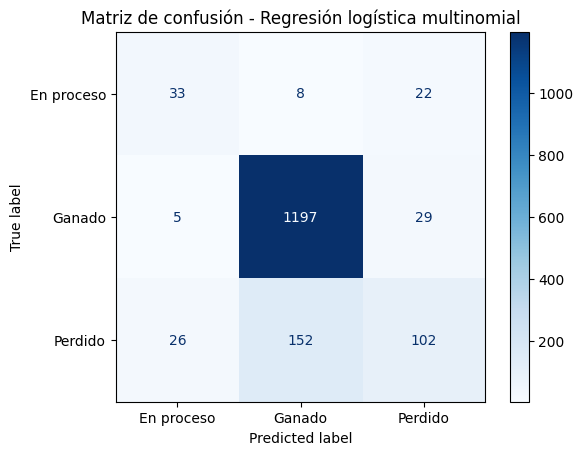

In [36]:
# Visualizamos la matriz de confusión
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=algoritmo.classes_
)
disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Regresión logística multinomial')
plt.show()

In [37]:
# Calculamos la precisión del modelo
# average='weighted' considera el número de observaciones de cada clase
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
print('Precisión ponderada del modelo:')
print(precision)

Precisión ponderada del modelo:
0.829102504656858


In [38]:
# Calculamos la exactitud del modelo
exactitud = accuracy_score(y_test, y_pred)
print('Exactitud del modelo:')
print(exactitud)

Exactitud del modelo:
0.8462515883100381


In [39]:
# Calculamos la sensibilidad (recall) ponderada
sensibilidad = recall_score(y_test, y_pred, average='weighted', zero_division=0)
print('Sensibilidad ponderada del modelo:')
print(sensibilidad)

Sensibilidad ponderada del modelo:
0.8462515883100381


In [40]:
# Calculamos el puntaje F1 ponderado
puntajef1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
print('Puntaje F1 ponderado del modelo:')
print(puntajef1)

Puntaje F1 ponderado del modelo:
0.8280683496127741


In [41]:
# Comparamos la exactitud contra la regla de la clase mayoritaria
# Es el mínimo que debe superar cualquier modelo útil
referencia = y_test.value_counts(normalize=True).max()
print('Exactitud de la clase mayoritaria:')
print(referencia)
print('Ganancia del modelo en puntos porcentuales:')
print((exactitud - referencia) * 100)

Exactitud de la clase mayoritaria:
0.7820838627700127
Ganancia del modelo en puntos porcentuales:
6.416772554002536


In [42]:
# Reporte de clasificación por cada categoría
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

  En proceso       0.52      0.52      0.52        63
      Ganado       0.88      0.97      0.93      1231
     Perdido       0.67      0.36      0.47       280

    accuracy                           0.85      1574
   macro avg       0.69      0.62      0.64      1574
weighted avg       0.83      0.85      0.83      1574



In [43]:
# Probabilidades estimadas para cada categoría
probabilidades = algoritmo.predict_proba(X_test)
df_probabilidades = pd.DataFrame(
    probabilidades,
    columns=[f'Probabilidad_{clase}' for clase in algoritmo.classes_]
)
df_probabilidades.head()

,Probabilidad_En proceso,Probabilidad_Ganado,Probabilidad_Perdido
0,0.005883,0.925067,0.069050
1,0.000148,0.898623,0.101228
2,0.000750,0.738717,0.260533
3,0.000281,0.937375,0.062345
4,0.000171,0.943896,0.055934


In [44]:
# Comparamos la categoría real con la categoría predicha
comparacion = pd.DataFrame({
    'Clase real': y_test.reset_index(drop=True),
    'Clase predicha': pd.Series(y_pred)
})
comparacion.head(10)

,Clase real,Clase predicha
0,Ganado,Ganado
1,Ganado,Ganado
2,Perdido,Ganado
3,Ganado,Ganado
4,Ganado,Ganado
5,Ganado,Ganado
6,En proceso,Ganado
7,Ganado,Ganado
8,Ganado,Ganado
9,Ganado,Ganado


**TABLA DE MÉTRICAS POR CATEGORÍA**

In [45]:
# Concentramos la precisión, la sensibilidad y el puntaje F1 de cada categoría
Tabla_Metricas = pd.DataFrame({
    'Categoría': algoritmo.classes_,
    'Registros en prueba': [int((y_test == clase).sum()) for clase in algoritmo.classes_],
    'Precisión': precision_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0),
    'Sensibilidad': recall_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0),
    'Puntaje F1': f1_score(y_test, y_pred, labels=algoritmo.classes_, average=None, zero_division=0)
})
Tabla_Metricas

,Categoría,Registros en prueba,Precisión,Sensibilidad,Puntaje F1
0,En proceso,63,0.515625,0.523810,0.519685
1,Ganado,1231,0.882093,0.972380,0.925039
2,Perdido,280,0.666667,0.364286,0.471132


In [46]:
# Agregamos las métricas globales del modelo
Tabla_Global = pd.DataFrame({
    'Métrica': ['Exactitud', 'Precisión ponderada', 'Sensibilidad ponderada',
                'Puntaje F1 ponderado', 'Puntaje F1 macro', 'Clase mayoritaria'],
    'Valor': [exactitud, precision, sensibilidad, puntajef1,
              f1_score(y_test, y_pred, average='macro', zero_division=0), referencia]
})
Tabla_Global

,Métrica,Valor
0,Exactitud,0.846252
1,Precisión ponderada,0.829103
2,Sensibilidad ponderada,0.846252
3,Puntaje F1 ponderado,0.828068
4,Puntaje F1 macro,0.638618
5,Clase mayoritaria,0.782084


**MODELO COMPLEMENTARIO CON CLASES BALANCEADAS**

La categoría Ganado concentra el 78 por ciento de los registros, por lo que el modelo anterior tiende a asignar esa categoría y deja con baja sensibilidad a Perdido y a En proceso. Ajustamos un segundo modelo que pondera cada clase de forma inversa a su frecuencia para medir ese efecto.

In [47]:
# Definimos el mismo algoritmo con ponderación inversa a la frecuencia de cada clase
algoritmo_balanceado = LogisticRegression(
    solver='lbfgs',
    max_iter=2000,
    class_weight='balanced'
)
algoritmo_balanceado.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [48]:
#Realizamos la predicción del modelo balanceado
y_pred_balanceado = algoritmo_balanceado.predict(X_test)

In [49]:
# Reporte de clasificación del modelo balanceado
print(classification_report(y_test, y_pred_balanceado, zero_division=0))

              precision    recall  f1-score   support

  En proceso       0.38      0.87      0.53        63
      Ganado       0.93      0.79      0.86      1231
     Perdido       0.42      0.58      0.49       280

    accuracy                           0.76      1574
   macro avg       0.58      0.75      0.63      1574
weighted avg       0.82      0.76      0.78      1574



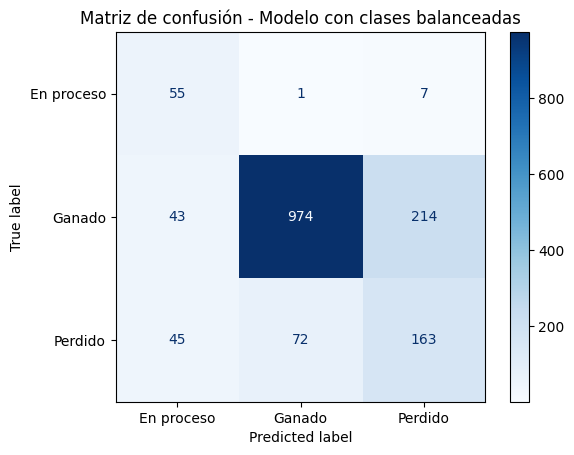

In [50]:
# Visualizamos la matriz de confusión del modelo balanceado
matriz_balanceada = confusion_matrix(y_test, y_pred_balanceado, labels=algoritmo_balanceado.classes_)
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=matriz_balanceada,
    display_labels=algoritmo_balanceado.classes_
)
disp2.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión - Modelo con clases balanceadas')
plt.show()

In [51]:
# Comparamos los dos modelos
Tabla_Comparacion = pd.DataFrame({
    'Modelo': ['Sin ponderación', 'Con clases balanceadas'],
    'Exactitud': [exactitud, accuracy_score(y_test, y_pred_balanceado)],
    'Puntaje F1 ponderado': [puntajef1,
                             f1_score(y_test, y_pred_balanceado, average='weighted', zero_division=0)],
    'Puntaje F1 macro': [f1_score(y_test, y_pred, average='macro', zero_division=0),
                         f1_score(y_test, y_pred_balanceado, average='macro', zero_division=0)],
    'Sensibilidad Perdido': [recall_score(y_test, y_pred, labels=['Perdido'], average=None, zero_division=0)[0],
                             recall_score(y_test, y_pred_balanceado, labels=['Perdido'], average=None, zero_division=0)[0]],
    'Sensibilidad En proceso': [recall_score(y_test, y_pred, labels=['En proceso'], average=None, zero_division=0)[0],
                                recall_score(y_test, y_pred_balanceado, labels=['En proceso'], average=None, zero_division=0)[0]]
})
Tabla_Comparacion

,Modelo,Exactitud,Puntaje F1 ponderado,Puntaje F1 macro,Sensibilidad Perdido,Sensibilidad En proceso
0,Sin ponderación,0.846252,0.828068,0.638618,0.364286,0.523810
1,Con clases balanceadas,0.757306,0.777499,0.626694,0.582143,0.873016


**COEFICIENTES DEL MODELO**

La regresión logística multinomial ajusta un vector de coeficientes por cada categoría. Un coeficiente positivo indica que al aumentar esa variable crece la probabilidad de la categoría correspondiente frente a las demás. Como las variables fueron escaladas, los coeficientes son comparables entre sí.

In [52]:
# Revisamos los coeficientes de cada categoría
Tabla_Coeficientes = pd.DataFrame(
    algoritmo.coef_.T,
    index=Vars_Indep.columns,
    columns=[f'Coeficiente_{clase}' for clase in algoritmo.classes_]
)
Tabla_Coeficientes.head(10)

,Coeficiente_En proceso,Coeficiente_Ganado,Coeficiente_Perdido
numero_actividades,0.764659,-1.482430,0.717772
log_valor,0.562101,-0.502995,-0.059106
tiene_valor,-0.571315,0.514811,0.056504
antiguedad_dias,-1.017384,0.504671,0.512713
mes_creacion,1.273262,-0.510191,-0.763071
tipo_negocio_Cliente nuevo,0.053194,-0.162838,0.109644
tipo_negocio_Sin dato,-0.014420,-0.190183,0.204604
nombre_pipeline_Pipeline De Ventas,-1.908911,1.559536,0.349375
nombre_pipeline_Sin dato,-0.023963,0.186303,-0.162340
nombre_pipeline_Ventas - Main,-1.099737,1.197866,-0.098129


In [53]:
# Consultamos las cinco variables de mayor peso para cada categoría
for k, clase in enumerate(algoritmo.classes_):
    pesos = Tabla_Coeficientes[f'Coeficiente_{clase}']
    print('---', clase)
    print(pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(5))
    print()

--- En proceso
nombre_pipeline_Pipeline De Ventas   -1.908911
mes_creacion                          1.273262
nombre_pipeline_Ventas - Main        -1.099737
antiguedad_dias                      -1.017384
numero_actividades                    0.764659
Name: Coeficiente_En proceso, dtype: float64

--- Ganado
nombre_pipeline_Pipeline De Ventas    1.559536
numero_actividades                   -1.482430
nombre_pipeline_Ventas - Main         1.197866
vendedor_Diego Rodríguez              0.933836
vendedor_Juan Cadena                  0.768630
Name: Coeficiente_Ganado, dtype: float64

--- Perdido
mes_creacion                                -0.763071
numero_actividades                           0.717772
vendedor_Diego Rodríguez                    -0.601663
nombre_zona_Zona Sur Este Golfo de México    0.563632
vendedor_Gerardo García                     -0.543891
Name: Coeficiente_Perdido, dtype: float64



In [54]:
# Revisamos el comportamiento de las variables numéricas en cada categoría
Tabla_Perfil = df.groupby('desenlace').agg(
    Registros=('desenlace', 'size'),
    Antiguedad_mediana_dias=('antiguedad_dias', 'median'),
    Actividades_mediana=('numero_actividades', 'median'),
    Proporcion_con_valor=('tiene_valor', 'mean')
).round(4)
Tabla_Perfil

,Registros,Antiguedad_mediana_dias,Actividades_mediana,Proporcion_con_valor
desenlace,,,,
En proceso,211,14.3553,2.0,0.2275
Ganado,4100,147.0360,0.0,0.1632
Perdido,934,128.6939,1.0,0.1959


**ANÁLISIS DE RESULTADOS**

El conjunto final quedó en 5245 registros y 39 variables predictoras, resultado de eliminar una columna sin nombre, 23 registros con las columnas desalineadas y la columna valor_negocio por ser idéntica a valor_previsto. Las fechas de creación abarcan de agosto de 2025 a septiembre de 2026.

La variable objetivo está muy desbalanceada. La categoría Ganado concentra 4100 registros que equivalen al 78.17 por ciento del total, Perdido reúne 934 registros con el 17.81 por ciento y En proceso apenas 211 registros con el 4.02 por ciento. Ese desbalance condiciona la lectura de todas las métricas.

El modelo alcanza una exactitud de 0.8463 frente a 0.7821 que obtendría la regla de asignar siempre la clase mayoritaria. La ganancia es de 6.42 puntos porcentuales, de modo que el modelo aporta información real pero moderada. La precisión ponderada es de 0.8291, la sensibilidad ponderada de 0.8463 y el puntaje F1 ponderado de 0.8281. El puntaje F1 macro, que trata a las tres categorías con el mismo peso, baja a 0.6386 y revela que el buen desempeño global descansa sobre la categoría mayoritaria.

El desglose por categoría confirma ese diagnóstico. Ganado obtiene una precisión de 0.8821 y una sensibilidad de 0.9724, por lo que el modelo identifica correctamente casi todos los negocios ganados. Perdido obtiene una precisión de 0.6667 pero una sensibilidad de solo 0.3643, es decir que el modelo detecta apenas un tercio de los negocios que efectivamente se perdieron. En proceso queda en un punto intermedio con 0.5156 de precisión y 0.5238 de sensibilidad sobre una base de 63 registros de prueba.

La matriz de confusión señala con precisión dónde falla el modelo. De los 280 negocios perdidos del conjunto de prueba, 102 se clasifican bien, 26 se asignan a En proceso y 152 se asignan a Ganado. Ese último bloque es el error dominante y el más costoso en términos de negocio, porque implica que el modelo pronostica un cierre favorable en negocios que terminaron perdiéndose. Un pronóstico con ese sesgo infla la expectativa de ingreso del pipeline.

**EFECTO DE LA PONDERACIÓN DE CLASES**

El modelo complementario con class_weight balanced invierte el compromiso. La sensibilidad de Perdido sube de 0.3643 a 0.5821 y la de En proceso sube de 0.5238 a 0.8730, lo que significa que el modelo ahora sí levanta la mayoría de los casos que antes pasaba por alto. El costo es que la exactitud cae a 0.7573, por debajo del 0.7821 de la clase mayoritaria, y el puntaje F1 macro baja ligeramente de 0.6386 a 0.6267 porque la precisión de las clases minoritarias se deteriora al emitir muchas más alertas.

Ninguno de los dos modelos domina al otro. La elección depende del uso: para estimar el volumen total de cierres conviene el modelo sin ponderación, y para detectar negocios en riesgo de perderse conviene el modelo ponderado, aceptando que generará falsas alarmas.

**LECTURA DE LOS COEFICIENTES**

Los coeficientes de mayor magnitud apuntan a nombre_pipeline, numero_actividades, antiguedad_dias y mes_creacion. El pipeline de ventas empuja con fuerza hacia Ganado con un coeficiente de 1.5595 y en contra de En proceso con menos 1.9089, lo que refleja que los negocios de ese canal se registran y cierran dentro del mismo flujo operativo. La antigüedad discrimina la categoría En proceso con un coeficiente de menos 1.0174, consistente con que los negocios abiertos son los más recientes: su antigüedad mediana es de 14.36 días contra 147.04 días en Ganado y 128.69 días en Perdido.

El hallazgo más llamativo es el signo de numero_actividades. Esta variable pesa menos 1.4824 para Ganado y más 0.7178 para Perdido, es decir que a mayor número de actividades registradas disminuye la probabilidad de un cierre favorable. La mediana de actividades es de cero en Ganado, uno en Perdido y dos en En proceso. La interpretación directa no es que dar seguimiento perjudique la venta, sino que los negocios que se ganan con facilidad se capturan en el CRM ya cerrados y sin actividades intermedias, mientras que los que exigen insistencia son precisamente los que se complican.

**CONCLUSIONES**

La regresión logística multinomial sobre la hoja Negocios_CRM supera la regla de la clase mayoritaria por 6.42 puntos de exactitud y distingue las tres categorías del desenlace, por lo que el ejercicio es válido. Dicho eso, el modelo solo es confiable para la categoría Ganado y presenta una debilidad clara en la detección de los negocios perdidos.

El desbalance de 78 contra 18 contra 4 por ciento es el principal limitante. Una exactitud de 0.8463 suena alta pero debe contrastarse siempre contra el 0.7821 del baseline, y el puntaje F1 macro de 0.6386 es la cifra que describe con honestidad el desempeño sobre las tres categorías. En problemas con esta estructura, reportar únicamente la exactitud transmite una impresión equivocada.

La calidad de los datos limita el alcance del modelo más que la técnica elegida. Veintitrés registros llegaron con las columnas desplazadas, varias columnas categóricas contenían valores de otras columnas, y el 83 por ciento de los negocios tiene valor previsto en cero, lo que vacía de contenido a la variable monetaria. Antes de refinar el modelo conviene corregir la captura en el origen.

Un punto metodológico que conviene explicitar: se descartaron estatus, motivo_cierre_perdido y cualquier variable derivada de fecha_cierre porque se escriben después del cierre y anticipan la respuesta. Al incluir los días de ciclo, la exactitud subía a 0.8602, pero esa ganancia es artificial y no estaría disponible al momento de pronosticar un negocio abierto. Se prefirió el modelo más conservador.

Queda abierta la observación sobre numero_actividades. El modelo aprende en buena medida el patrón de captura del CRM, donde las ventas que se cierran de inmediato se registran sin actividades previas. Eso significa que el modelo describe mejor cómo se registra la operación que cómo se comporta un negocio a futuro. Para un pronóstico genuinamente anticipado haría falta reconstruir el estado de cada negocio en un momento previo a su cierre y entrenar únicamente con la información disponible en esa fecha.